<a href="https://colab.research.google.com/github/rahs2015/mat422/blob/main/MAT422_%7C_HW_1_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT 422 | HW 1.3.1-3: Linear Algebra & Python

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# 1.3.1 | QR Decomposition





In this example, a 4 by 2 matrix factored into A = QR where Q is the orthogonal matrix and R is the upper triangular matrix. Using the idea of QR decomposition of which it says Q^T @ Q = I and Q @ R = A, it is possible to confirm through approximation the QR decomposition is valid.  

In [6]:
x = np.array([
    [1,2], [2,1], [3,4],[4,3]], dtype=float)
q,r = np.linalg.qr(x)

print("4 x 2 Matrix:\n",x)
print("\n\n4 x 2 Orthogonal Matrix (Q):\n", q)
print("\n\nUpper Triangle Matrix (R):\n",r)

#verification
print("\n\nVerification of Decomposition \n   (using Q @ Q^T = I & Q @ R = A)")
veriOrtho = np.allclose(q.T @ q, np.eye(q.shape[1]))
print("\nDoes Q have orthonormal columns? (T/F): ", veriOrtho)
if (veriOrtho == True):
  print("  Q.T @ Q = \n", q.T @ q)

veriRecon = np.allclose(q @ r, x)
print("\nDoes Q @ R reconstruct into A? (T/F): ", veriRecon)
if (veriRecon == True):
  print("  Q @ R = \n", q @ r)


4 x 2 Matrix:
 [[1. 2.]
 [2. 1.]
 [3. 4.]
 [4. 3.]]


4 x 2 Orthogonal Matrix (Q):
 [[-0.18257419  0.5424508 ]
 [-0.36514837 -0.44074128]
 [-0.54772256  0.61025715]
 [-0.73029674 -0.37293493]]


Upper Triangle Matrix (R):
 [[-5.47722558 -5.1120772 ]
 [ 0.          1.96638416]]


Verification of Decomposition 
   (using Q @ Q^T = I & Q @ R = A)

Does Q have orthonormal columns? (T/F):  True
  Q.T @ Q = 
 [[1.00000000e+00 7.85504034e-17]
 [7.85504034e-17 1.00000000e+00]]

Does Q @ R reconstruct into A? (T/F):  True
  Q @ R = 
 [[1. 2.]
 [2. 1.]
 [3. 4.]
 [4. 3.]]


## 1.3.2 | Least Squares Problem

With an overdetermined matrix (basically a tall matrix), one can find a vector that minimizes the residual norm. This allows to find the best fit line of a set of data. In this example, it is verified that A.T @ residual is approximately 0 which confimrs that our residual vector is orthongal to the A's columns space. Upon examining the output, it is seens that A^T @ r is close to the 0 which holds a strong argument that our residual is orthogonal to A's columns space. The QR and Singular value Decomposition additionally provide another layer of assurance that proves that our standard least squares test is valid.

In [7]:
from matplotlib.cbook import print_cycles
X = np.array([
    [1,1,2],
    [1,2,1],
    [1,3,4],
    [1,4,3],
    [1,5,5]
], dtype = float)

y = np.array([1.6, 3.8, 5.5, 7.9, 8.5], dtype = float)
xLtSq, resSum, rank, singVals = np.linalg.lstsq(X, y, rcond = None)
resid = y - X @ xLtSq
resNorm = np.linalg.norm(resid)


print ("- Least Squares -")

print("Least squares solution:      ", xLtSq)
print("Residual vector (b - A @ X): ", resid)
print("Residual norm:               ", resNorm)
print("Rank of Matrix:              ", rank)
print("A.T @ residual ≈ 0 (T/F):     ", np.allclose(X.T@resid,0))

#Least squares through single value decomposition
u, s, vt = np.linalg.svd(X, full_matrices= False)

xSVD= vt.T @ ((u.T@y)/s)
residSVD = y - X @ xSVD
residNormSVD = np.linalg.norm(residSVD)


print ("\n\n- Least Squares: QR decomposition -")
qls,rls = np.linalg.qr(X)
yProj= qls.T @ y
xQr = np.linalg.solve(rls, yProj)

print("QR solution:                         ", xQr)
print("QR solutions ≈ Least Squares? (T/F): ", np.allclose(xQr, xLtSq))



print ("\n\n- Least Squares: SVD Method -")

print("SVD solution:              ", xSVD)
print("SVD Residual Norm:         ", residNormSVD)
print("SVD ≈ Least Square? (T/F): ", np.allclose(xSVD, xLtSq))




- Least Squares -
Least squares solution:       [ 0.26        2.01666667 -0.28333333]
Residual vector (b - A @ X):  [-0.11       -0.21        0.32333333  0.42333333 -0.42666667]
Residual norm:                0.722495674727538
Rank of Matrix:               3
A.T @ residual ≈ 0 (T/F):      True


- Least Squares: QR decomposition -
QR solution:                          [ 0.26        2.01666667 -0.28333333]
QR solutions ≈ Least Squares? (T/F):  True


- Least Squares: SVD Method -
SVD solution:               [ 0.26        2.01666667 -0.28333333]
SVD Residual Norm:          0.7224956747275376
SVD ≈ Least Square? (T/F):  True


## 1.3.3 | Linear Regression

Linear Regressions can use the idea of least squares as they are meant to minimize the total residuals error. Through a design matrix with columns of ones and predictor values, it is possible to run a line through our data points that minimizes a matrix's residual. In the example with profits from amount of items sold, the y intercept and slope are printed and were used to predict potential profits under  higher sales. The orange lines are shown for visualization of the residual and the blue is depicted as the best fit line.

Design Matrix X = 
 [[ 1. 10.]
 [ 1. 20.]
 [ 1. 30.]
 [ 1. 40.]
 [ 1. 50.]
 [ 1. 60.]
 [ 1. 70.]
 [ 1. 80.]]


Intercept:               8.892857142857148
Slope:                   0.6940476190476189

Fitted Y line:           [15.83333333 22.77380952 29.71428571 36.6547619  43.5952381  50.53571429
 57.47619048 64.41666667]
Residual Error.          [-3.83333333  3.22619048  3.28571429  0.3452381  -2.5952381  -1.53571429
  0.52380952  0.58333333]

Root mean square error:  2.3907684558576157


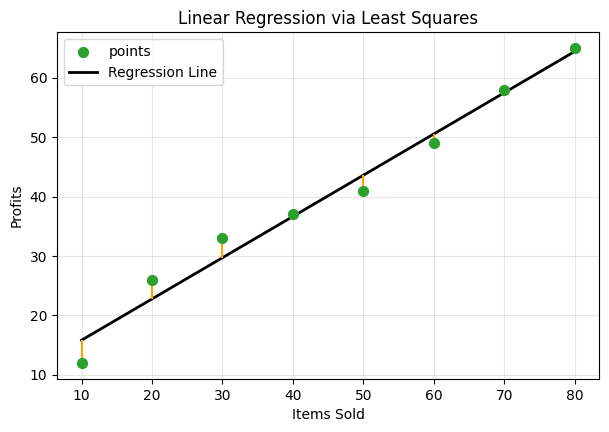

In [8]:
x = np.array([10,20,30,40,50,60,70,80], dtype = float)
data = np.array([12,26,33,37,41,49,58,65], dtype = float)

x1 = np.column_stack([np.ones_like(x),x])
beta,_,_,_ = np.linalg.lstsq(x1,data, rcond = None)

dataPred = x1 @ beta
resid = data - dataPred
error = np.sqrt(np.mean(resid**2))

print("Design Matrix X = \n",x1)
print("\n\nIntercept:              ", beta[0])
print("Slope:                  ", beta[1])
print("\nFitted Y line:          ", dataPred)
print("Residual Error.         ", resid)
print("\nRoot mean square error: ", error)


#Graphical Display
plt.figure(figsize=(7,4.5))
plt.scatter(x, data, color = "tab:green", label="points", s=50, zorder =3)
plt.plot(x,dataPred, color="black", label= f"Regression Line", linewidth=2)

for i in range(len(data)):
    plt.vlines(x[i],data[i], dataPred[i], color="orange")

plt.xlabel("Items Sold")
plt.ylabel("Profits")
plt.title("Linear Regression via Least Squares")
plt.grid(True, alpha =.3)
plt.legend()
plt.show()

* I explained my sections in words before my code.
* I double checked my core numerical claims such as expression, matrix multiplication, norms, ...
* I changed and/or extended at least one to make this homework my own.
* I ran this from to bottom without issues.
* I am saving this to github under my mat422 repository.